In [1]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
!pip install -q --upgrade kaggle

In [3]:
from google.colab import files
files.upload()

Saving kaggle (2).json to kaggle (2).json


{'kaggle (2).json': b'{"username":"nnm24am016bhumikacs","key":"fb8554b1b73fcf92d6462f65c11e1f11"}'}

In [4]:
import os
os.rename("kaggle (2).json", "kaggle.json")
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [5]:
!kaggle datasets list -s "chest xray pneumonia"

ref                                                             title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
divyam6969/chest-xray-pneumonia-dataset                         Chest XRAY - Pneumonia Dataset                       1151535496  2024-01-17 12:19:16.570000           1531         30  0.6875           
kostasdiamantaras/chest-xrays-bacterial-viral-pneumonia-normal  Chest Xrays: bacterial / viral pneumonia / normal    1222999548  2020-10-27 16:51:15.783000           2393         22  0.7058824        
amanullahasraf/covid19-pneumonia-normal-chest-xray-pa-dataset   COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset       2053474983  2020-07-13 05:54:22.483000           4421         35  0.8125       

In [6]:
!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
chest-xray-pneumonia.zip: Skipping, found more recently modified local copy (use --force to force download)


In [7]:
!unzip -q chest-xray-pneumonia.zip

replace chest_xray/__MACOSX/._chest_xray? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [8]:
import os
print(os.listdir('/content/chest_xray'))

['chest_xray', 'test', '__MACOSX', 'train', 'val']


In [9]:
print(os.listdir('/content/chest_xray/train'))

['NORMAL', 'PNEUMONIA']


In [25]:
# CNN

In [10]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [11]:
train_dir = '/content/chest_xray/train'
val_dir = '/content/chest_xray/val'
test_dir = '/content/chest_xray/test'

In [12]:
IMG_SIZE = 224
BATCH_SIZE = 32

In [13]:
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

In [14]:
train_data = train_datagen.flow_from_directory(
    train_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

val_data = val_datagen.flow_from_directory(
    val_dir, target_size=(224,224), batch_size=32, class_mode='binary'
)

test_data = test_datagen.flow_from_directory(
    test_dir, target_size=(224,224), batch_size=32, class_mode='binary',shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


In [15]:
print(train_data.class_indices)

{'NORMAL': 0, 'PNEUMONIA': 1}


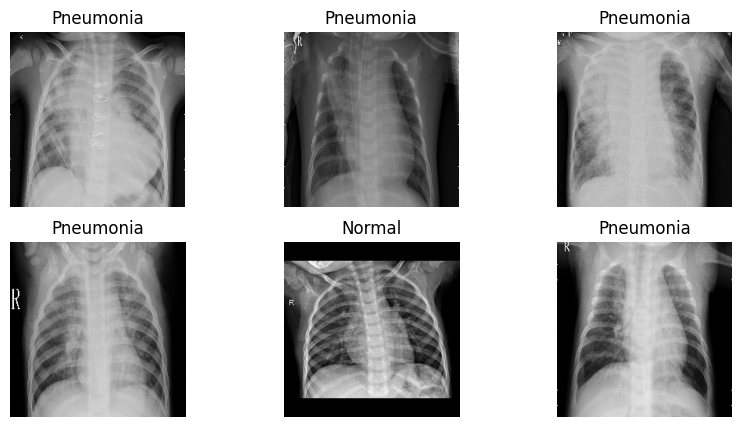

In [16]:
images, labels = next(train_data)

plt.figure(figsize=(10,5))

for i in range(6):
    plt.subplot(2,3,i+1)
    plt.imshow(images[i])
    plt.title("Pneumonia" if labels[i] == 1 else "Normal")
    plt.axis("off")

plt.show()

In [17]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 186624)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    23,888,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,907,521 (91.20 MB)

 Trainable params: 23,907,521 (91.20 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [19]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 67s 375ms/step - accuracy: 0.9126 - loss: 0.3406 - val_accuracy: 0.7500 - val_loss: 0.5243
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 66s 403ms/step - accuracy: 0.9726 - loss: 0.0787 - val_accuracy: 0.8125 - val_loss: 0.2993
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 364ms/step - accuracy: 0.9824 - loss: 0.0482 - val_accuracy: 0.7500 - val_loss: 0.2544
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 61s 373ms/step - accuracy: 0.9900 - loss: 0.0282 - val_accuracy: 0.8125 - val_loss: 0.3718
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 360ms/step - accuracy: 0.9883 - loss: 0.0317 - val_accuracy: 0.8750 - val_loss: 0.3700
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 61s 373ms/step - accuracy: 0.9952 - loss: 0.0140 - val_accuracy: 0.8125 - val_loss: 0.9841
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 59s 364ms/step - accuracy: 0.9990 - loss: 0.0053 - val_accuracy: 0.8750 - val_loss: 0.5948
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 61s 371ms/step - accuracy: 0.9988 - loss: 0

In [20]:
test_loss, test_accuracy = model.evaluate(test_data)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 229ms/step - accuracy: 0.7260 - loss: 3.4133
Test Loss: 3.413255453109741
Test Accuracy: 0.7259615659713745


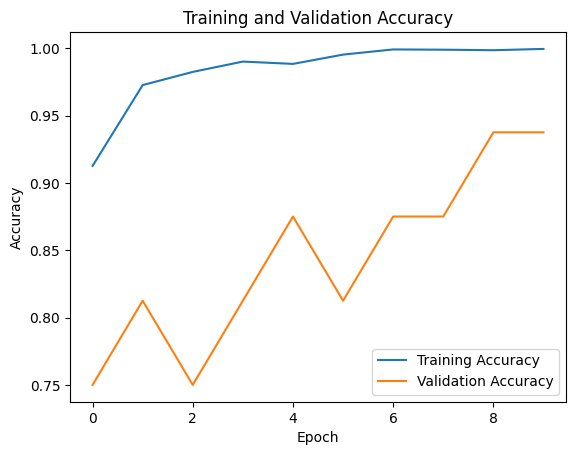

In [21]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

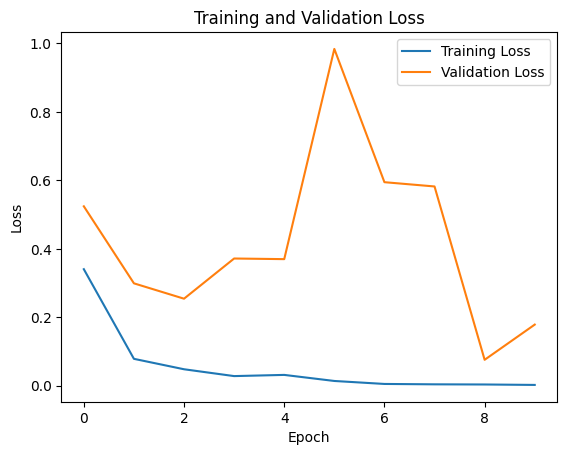

In [22]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

20/20 ━━━━━━━━━━━━━━━━━━━━ 7s 320ms/step


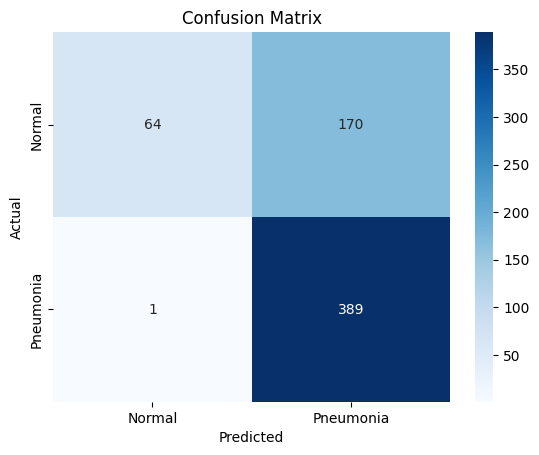

In [23]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

pred = model.predict(test_data)
pred = (pred > 0.5).astype(int)

cm = confusion_matrix(test_data.classes, pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal', 'Pneumonia'],
            yticklabels=['Normal', 'Pneumonia'])

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [24]:
from sklearn.metrics import classification_report

print(classification_report(
    test_data.classes,
    pred,
    target_names=['Normal', 'Pneumonia']
))

              precision    recall  f1-score   support

      Normal       0.98      0.27      0.43       234
   Pneumonia       0.70      1.00      0.82       390

    accuracy                           0.73       624
   macro avg       0.84      0.64      0.62       624
weighted avg       0.80      0.73      0.67       624



In [26]:
# TRANSFER LEARNING

In [27]:
from tensorflow.keras.applications import VGG16

In [28]:
base_model = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [29]:
base_model.trainable = False

In [30]:
model = tf.keras.Sequential([
    base_model,
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

In [31]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,926,209 (68.38 MB)

 Trainable params: 3,211,521 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [32]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [33]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 102s 538ms/step - accuracy: 0.9377 - loss: 0.2102 - val_accuracy: 0.8750 - val_loss: 0.1997
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 67s 411ms/step - accuracy: 0.9804 - loss: 0.0548 - val_accuracy: 0.8750 - val_loss: 0.2814
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 397ms/step - accuracy: 0.9893 - loss: 0.0335 - val_accuracy: 0.7500 - val_loss: 0.7068
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 400ms/step - accuracy: 0.9875 - loss: 0.0341 - val_accuracy: 0.7500 - val_loss: 0.6281
Epoch 5/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 398ms/step - accuracy: 0.9948 - loss: 0.0170 - val_accuracy: 0.8750 - val_loss: 0.2649
Epoch 6/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 400ms/step - accuracy: 0.9973 - loss: 0.0103 - val_accuracy: 0.8750 - val_loss: 0.2234
Epoch 7/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 65s 398ms/step - accuracy: 0.9996 - loss: 0.0053 - val_accuracy: 0.9375 - val_loss: 0.1041
Epoch 8/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 64s 394ms/step - accuracy: 1.0000 - loss: 

In [34]:
test_loss, test_accuracy = model.evaluate(test_data)
print("Test Accuracy:", test_accuracy * 100)

20/20 ━━━━━━━━━━━━━━━━━━━━ 8s 277ms/step - accuracy: 0.7484 - loss: 1.7039
Test Accuracy: 74.83974099159241


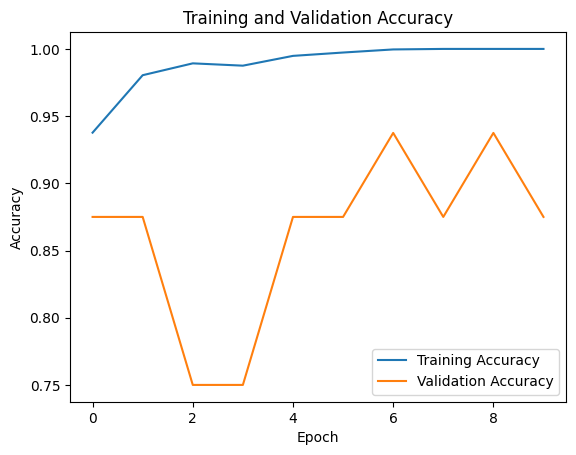

In [36]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

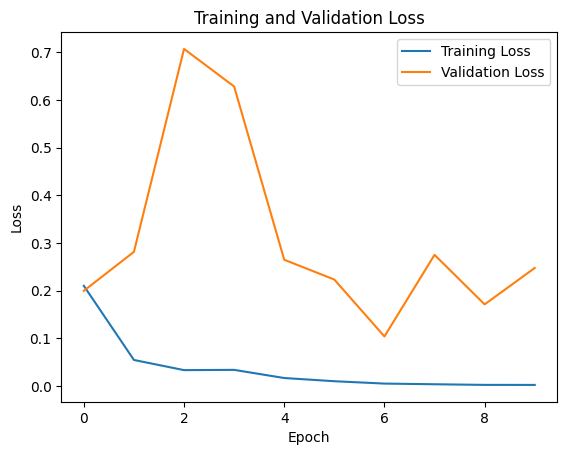

In [37]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 389ms/step


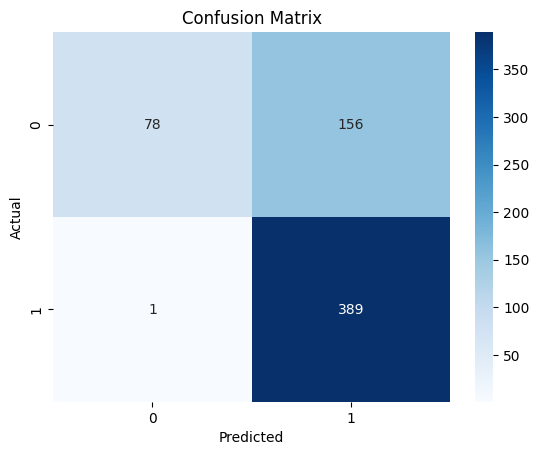

In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

pred = model.predict(test_data)
pred = (pred > 0.5).astype(int)

cm = confusion_matrix(test_data.classes, pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [39]:
from sklearn.metrics import classification_report

print(classification_report(
    test_data.classes,
    pred,
    target_names=['Normal', 'Pneumonia']
))

              precision    recall  f1-score   support

      Normal       0.99      0.33      0.50       234
   Pneumonia       0.71      1.00      0.83       390

    accuracy                           0.75       624
   macro avg       0.85      0.67      0.67       624
weighted avg       0.82      0.75      0.71       624

